# Tutorial: descriptive & inferential statistics with `pandas`, `matplotlib` and `scipy` (Level 3)

This notebook is a **method guide**. It walks through a complete (small) analysis on a **synthetic example dataset**, so you can see *what to do, why, and how to read the output*.

> ⚠️ **How to use it.** All numbers here come from *fictional* data. Learn the method here, then apply the same steps to **your own** question and dataset. Your report must be your own analysis (and, per the assignment, written in correct French).

**Libraries (Level 3):** `pandas` (data), `matplotlib` (graphs), `scipy` (tests and regression). `numpy` is installed automatically with them.

## Contents
0. Setup and configuration
1. Context and research questions
2. The dataset: granularity and variables
3. Loading the raw CSV
4. Data quality: finding problems and cleaning
5. Descriptive statistics and graphs
6. Hypothesis test, step by step (Welch t-test)
7. A second test: chi-square (two qualitative variables)
8. Simple linear regression
9. Conclusion template, checklist and "which test when?" cheat sheet

Every part follows the same pattern: **what** we do → **why** → **code** → **how to read the result**.

## 0. Setup and configuration

Install once (in a terminal), then restart the notebook:

```bash
pip install pandas matplotlib scipy notebook
```

The next cell imports the libraries and prints their versions. **Always note your versions** in a report: results and even function behaviour can change between releases.

In [ ]:
# Setup: imports, versions and a readable plot style.

import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

print("python     :", sys.version.split()[0])
for module in (np, pd, matplotlib, scipy):
    print(f"{module.__name__:<11}:", module.__version__)


python     : 3.12.3
numpy      : 2.5.4
pandas     : 3.1.1
matplotlib : 3.11.2
scipy      : 1.18.1


### Configuration: the only cell to edit for your own data

All the code below refers to **column names stored as constants**. To reuse the notebook on another CSV, change this cell (and skip the "synthetic generator" cell of Part 2). The rest of the notebook then runs unchanged, as long as your data has the same *shape*: one qualitative variable with 2 groups, two quantitative variables and one more qualitative variable.

In [ ]:
# Configuration: edit this cell to reuse the notebook on your own dataset.

CSV_RAW = "students_raw.csv"      # raw file: never edit it by hand
CSV_CLEAN = "students_clean.csv"  # cleaned copy written by this notebook

GROUP_COL = "method"              # qualitative variable with exactly 2 groups
VALUE_COL = "exam_score"          # quantitative outcome compared between the groups
X_COL = "study_hours"             # quantitative explanatory variable (regression)
CATEGORY_COL = "passed"           # second qualitative variable (chi-square)
POSITIVE_CATEGORY = "yes"         # value of CATEGORY_COL counted as a "success"

REFERENCE_GROUP = "A"             # baseline group
TREATED_GROUP = "B"               # group expected to do better

VALUE_MIN, VALUE_MAX = 0, 20      # legal range of VALUE_COL (used by the quality check)
ALPHA = 0.05                      # significance level, fixed BEFORE looking at the results


## 1. Context and research questions

**Fictional context.** A university wants to know whether a new revision method (**B**) helps students more than the classic method (**A**). 120 students were *randomly assigned* to one of the two methods. At the end of the term we record their weekly study hours and their exam score (out of 20).

**Questions.** Each one needs a different statistical tool, which is exactly what the assignment asks you to practise:

| # | Question | Variables | Tool |
|---|---|---|---|
| Q1 | Is the mean exam score higher with method B than with A? | `exam_score` (quantitative) by `method` (2 groups) | Welch t-test (Part 6) |
| Q2 | Is the pass rate linked to the method? | `passed` × `method` (both qualitative) | chi-square test (Part 7) |
| Q3 | Do more study hours go with a higher score? | `study_hours` × `exam_score` (both quantitative) | simple linear regression (Part 8) |

> **For your own project:** write the context in a few lines, say *why it matters to you*, and phrase 1 to 3 questions that need a statistical tool. A good question names the variables and the comparison.

## 2. The dataset: granularity and variables

**Granularity.** One row = **one student**. This is the *unit of analysis*. Always say it explicitly: it decides what "n" means. (If a row were "one country in one year", n would count country-years, not countries.)

**Where does the file come from?** The next cell *simulates* a raw file and writes it to disk. It contains a few **deliberate flaws** (missing values, a duplicated row, an impossible score, an extreme value) so that Part 4 has something to find. The simulation also builds in a **+2.0 point advantage for method B**: unlike in real life, here we know the truth, which lets us check our conclusions at the end of Part 6.

> **Skip this cell if you use your own CSV**, and cite your data source in your report (the assignment requires it).

In [3]:
"""/**
 * SYNTHETIC raw dataset generator (skip it for real data).
 * The random seed makes the file identical on every run.
 */"""
SEED = 2026
N_PER_METHOD = 60
TRUE_EFFECT_B = 2.0   # built-in advantage of method B, in points (we know the truth here)
N_STUDENTS = 2 * N_PER_METHOD
rng = np.random.default_rng(SEED)

method = np.repeat(["A", "B"], N_PER_METHOD)
study_hours = np.clip(rng.normal(12, 4, N_STUDENTS), 1, 30).round(1)
exam_score = 5 + 0.45 * study_hours + TRUE_EFFECT_B * (method == "B") + rng.normal(0, 1.8, N_STUDENTS)
exam_score = np.clip(exam_score, 0, 20).round(1)

students = pd.DataFrame({
    "student_id": np.arange(1, N_STUDENTS + 1),
    "method": method,
    "study_hours": study_hours,
    "exam_score": exam_score,
    "passed": np.where(exam_score >= 10, "yes", "no"),
})
students = students.sample(frac=1, random_state=SEED).reset_index(drop=True)  # shuffle the rows

"""/** Deliberate flaws: 8 distinct rows are damaged, a 9th row is duplicated. */"""
damaged = rng.choice(N_STUDENTS, size=8, replace=False)
untouched = np.setdiff1d(np.arange(N_STUDENTS), damaged)
students.loc[damaged[:6], "study_hours"] = np.nan   # 6 missing values
students.loc[damaged[6], "exam_score"] = 25.0       # impossible: the maximum mark is 20
students.loc[damaged[7], "study_hours"] = 40.0      # extreme, but not impossible
students = pd.concat([students, students.iloc[[rng.choice(untouched)]]], ignore_index=True)

students.to_csv(CSV_RAW, index=False)
print(f"{CSV_RAW} written: {students.shape[0]} rows, {students.shape[1]} columns")


students_raw.csv written: 121 rows, 5 columns


### Data dictionary

Before any analysis, list every variable with its **type** and **meaning**. The type decides which graphs and tests are allowed:

- *quantitative* (numbers you can average): mean, histogram, regression;
- *qualitative* (categories): counts, proportions, bar chart, chi-square;
- *identifier*: never analysed, only used to spot duplicates.

In [4]:
data_dictionary = pd.DataFrame(
    [
        ("student_id", "identifier", "Unique student number", "-"),
        ("method", "qualitative (nominal)", "Revision method: A = classic, B = new", "-"),
        ("study_hours", "quantitative (continuous)", "Weekly study hours during the term", "hours / week"),
        ("exam_score", "quantitative (continuous)", "Final exam mark", "points out of 20"),
        ("passed", "qualitative (binary)", "'yes' when exam_score >= 10", "-"),
    ],
    columns=["variable", "type", "meaning", "unit"],
)
data_dictionary


,variable,type,meaning,unit
0,student_id,identifier,Unique student number,-
1,method,qualitative (nominal),"Revision method: A = classic, B = new",-
2,study_hours,quantitative (continuous),Weekly study hours during the term,hours / week
3,exam_score,quantitative (continuous),Final exam mark,points out of 20
4,passed,qualitative (binary),'yes' when exam_score >= 10,-


## 3. Loading the raw CSV

`pd.read_csv` reads the file into a **DataFrame** (a table). First look at three things: the **shape** (rows × columns), the **types** and the first rows.

How to read `info()`: *Non-Null Count* lower than the number of rows means missing values; the *Dtype* column tells you whether pandas understood each column (numbers should be `float64`/`int64`, text is `str`).

> With pandas 3.x text columns show as `str`; older tutorials show `object` for the same thing.

In [5]:
df_raw = pd.read_csv(CSV_RAW)
print("rows, columns:", df_raw.shape)
df_raw.info()


rows, columns: (121, 5)
<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   student_id   121 non-null    int64  
 1   method       121 non-null    str    
 2   study_hours  115 non-null    float64
 3   exam_score   121 non-null    float64
 4   passed       121 non-null    str    
dtypes: float64(2), int64(1), str(2)
memory usage: 4.9 KB


In [6]:
df_raw.head()

,student_id,method,study_hours,exam_score,passed
0,54,A,16.0,14.5,yes
1,43,A,8.7,10.6,yes
2,17,A,10.4,11.2,yes
3,62,B,8.0,11.7,yes
4,47,A,NaN,15.7,yes


## 4. Data quality: finding problems and cleaning

The assignment asks you to **criticise the quality of the data**. A good critique is concrete: *what* is wrong, *how many* rows, *what you decided* and *why*. We check four families of problems.

### 4.1 Missing values
`isna().sum()` counts empty cells per column. Ask yourself *why* they are missing (random? systematic?), because it changes what is safe to do.

In [7]:
missing = df_raw.isna().sum()
missing_report = pd.DataFrame({"missing": missing, "percent": (missing / len(df_raw) * 100).round(1)})
missing_report


,missing,percent
student_id,0,0.0
method,0,0.0
study_hours,6,5.0
exam_score,0,0.0
passed,0,0.0


### 4.2 Duplicated rows
An exact duplicate usually means the same record was entered twice. It would count one student twice and slightly distort every statistic.

In [8]:
duplicates = df_raw[df_raw.duplicated(keep=False)]
print("rows involved in duplicates:", len(duplicates))
duplicates


rows involved in duplicates: 2


,student_id,method,study_hours,exam_score,passed
52,1,A,8.8,11.0,yes
120,1,A,8.8,11.0,yes


### 4.3 Impossible values
Compare each variable with what is *possible* in the real world (here: an exam mark must be between 0 and 20). An impossible value is an **error**, not an outlier.

In [9]:
out_of_range = ~df_raw[VALUE_COL].between(VALUE_MIN, VALUE_MAX)
print(f"{VALUE_COL} outside [{VALUE_MIN}, {VALUE_MAX}]:", int(out_of_range.sum()), "row(s)")
df_raw[out_of_range]


exam_score outside [0, 20]: 1 row(s)


,student_id,method,study_hours,exam_score,passed
117,27,A,9.1,25.0,yes


### 4.4 Outliers (possible but extreme values)
The **IQR rule** flags a value as an outlier when it lies more than 1.5 × IQR beyond the quartiles:

$$ x < Q_1 - 1.5\,\text{IQR} \quad\text{or}\quad x > Q_3 + 1.5\,\text{IQR}, \qquad \text{IQR} = Q_3 - Q_1 $$

An outlier is **not automatically an error**. Flag it, look at it, then decide.

In [10]:
def iqr_outlier_mask(values, factor=1.5):
    """/** True for values outside [Q1 - factor*IQR, Q3 + factor*IQR]; NaN is never flagged. */"""
    q1, q3 = values.quantile([0.25, 0.75])
    spread = q3 - q1
    return (values < q1 - factor * spread) | (values > q3 + factor * spread)


for column in (X_COL, VALUE_COL):
    flagged = df_raw[iqr_outlier_mask(df_raw[column])]
    print(f"{column}: {len(flagged)} flagged value(s) ->", flagged[column].tolist())


study_hours: 2 flagged value(s) -> [40.0, 24.6]
exam_score: 3 flagged value(s) -> [3.5, 3.4, 25.0]


### 4.5 Cleaning decisions (write them down!)

| Problem | Decision | Why |
|---|---|---|
| Exact duplicate | **Remove** the extra copy | Same record entered twice |
| Impossible score (> 20) | **Remove** the row | Certain data-entry error; we cannot guess the true mark |
| Missing `study_hours` | **Keep** the row, drop it *only* in analyses that need hours | The score is still valid for the t-test and chi-square; dropping globally would waste data |
| Extreme `study_hours` | **Keep**, then test whether it matters (Part 8) | Not impossible; removing it without reason would be cherry-picking |
| Scores flagged by the IQR rule but inside 0 to 20 | **Keep** | Very low or very high marks are valid; students really differ |

A **cleaning log** (rows before / after each step) makes the process auditable. The raw file is never modified: we write a separate cleaned file.

In [11]:
cleaning_log = [("raw file", len(df_raw))]

df = df_raw.drop_duplicates()
cleaning_log.append(("after removing exact duplicates", len(df)))

"""/** between() is False for NaN, so a missing score would also be dropped here (wanted for Q1). */"""
df = df[df[VALUE_COL].between(VALUE_MIN, VALUE_MAX)].copy()
cleaning_log.append(("after removing impossible scores", len(df)))

df.to_csv(CSV_CLEAN, index=False)
print(f"{CSV_CLEAN} written")
pd.DataFrame(cleaning_log, columns=["step", "rows left"])


students_clean.csv written


,step,rows left
0,raw file,121
1,after removing exact duplicates,120
2,after removing impossible scores,119


## 5. Descriptive statistics and graphs

**Goal:** describe the data before testing anything. Numbers and graphs answer different questions, so use both.

### 5.1 Quantitative variables
`describe()` gives count, mean, standard deviation, min, quartiles and max. Compare **mean and median**: a big gap hints at skewness or outliers. The **standard deviation** measures spread around the mean.

In [12]:
df[[X_COL, VALUE_COL]].describe().round(2)

,study_hours,exam_score
count,113.00,119.00
mean,12.50,11.65
std,4.84,2.83
min,2.80,3.40
25%,9.40,10.05
50%,11.90,11.80
75%,14.90,13.45
max,40.00,18.60


The same summary **by group** is the first (informal) answer to Q1: do the two groups look different?

In [13]:
by_group = df.groupby(GROUP_COL)[VALUE_COL].agg(["count", "mean", "std", "median", "min", "max"])
by_group.round(2)


,count,mean,std,median,min,max
method,,,,,,
A,59,11.07,2.92,11.0,3.5,18.6
B,60,12.23,2.65,12.2,3.4,17.9


### 5.2 Qualitative variables
For categories we use **counts** and **proportions** (never a mean). A *contingency table* (`crosstab`) counts every combination of two categorical variables; `normalize="index"` turns each row into percentages.

In [14]:
counts = pd.crosstab(df[GROUP_COL], df[CATEGORY_COL], margins=True)
percent_by_group = (pd.crosstab(df[GROUP_COL], df[CATEGORY_COL], normalize="index") * 100).round(1)
print("Counts:")
print(counts)
print("\nRow percentages (% of each method):")
print(percent_by_group)


Counts:
passed  no  yes  All
method              
A       19   40   59
B        9   51   60
All     28   91  119

Row percentages (% of each method):
passed    no   yes
method            
A       32.2  67.8
B       15.0  85.0


### 5.3 Graphs
Four classic views, each answering one question:

| Graph | Variable(s) | What to look at |
|---|---|---|
| Histogram | 1 quantitative | Shape (symmetric? skewed?), centre, spread |
| Boxplot | quantitative by group | Median, quartiles, outliers, group comparison |
| Scatter plot | 2 quantitative | Direction and strength of a relationship |
| Bar chart | qualitative | Proportions per category |

Always label axes (with units) and give each graph a title.

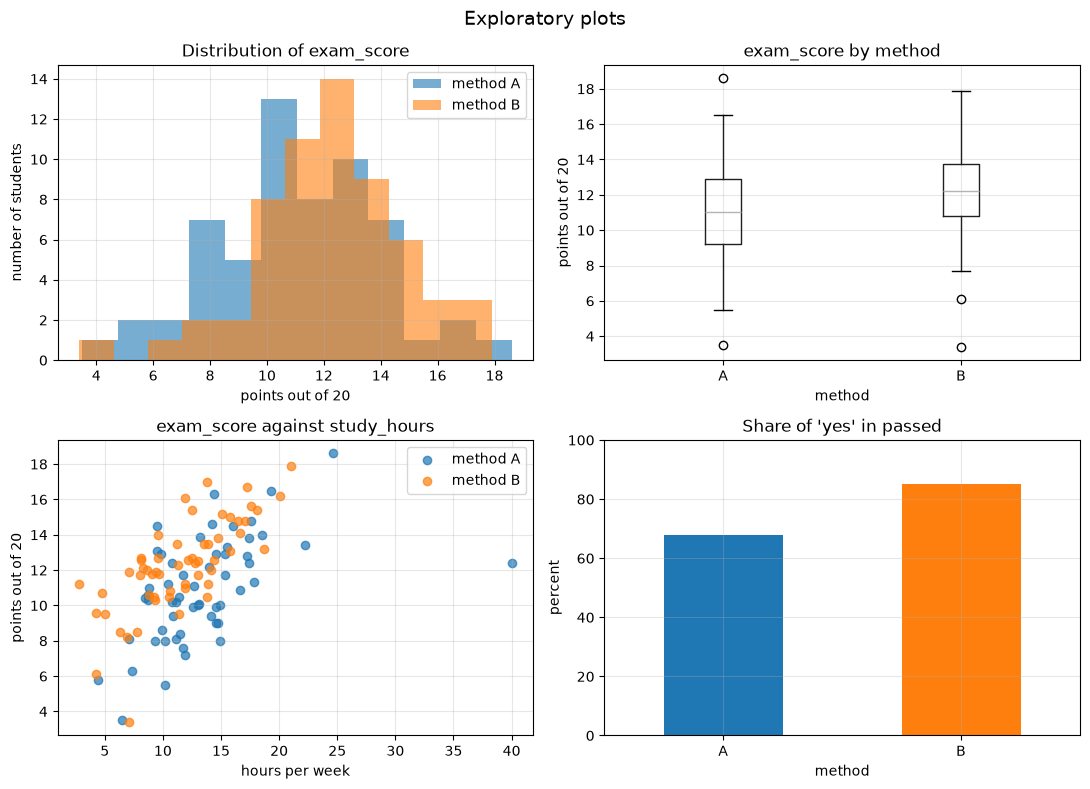

In [15]:
groups = sorted(df[GROUP_COL].unique())
pass_rate = (df[CATEGORY_COL] == POSITIVE_CATEGORY).groupby(df[GROUP_COL]).mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

"""/** 1. Histogram of the outcome, one colour per group. */"""
for group in groups:
    axes[0, 0].hist(df.loc[df[GROUP_COL] == group, VALUE_COL], bins=12, alpha=0.6, label=f"{GROUP_COL} {group}")
axes[0, 0].set(title=f"Distribution of {VALUE_COL}", xlabel="points out of 20", ylabel="number of students")
axes[0, 0].legend()

"""/** 2. Boxplot of the outcome by group. */"""
df.boxplot(column=VALUE_COL, by=GROUP_COL, ax=axes[0, 1])
axes[0, 1].set(title=f"{VALUE_COL} by {GROUP_COL}", xlabel=GROUP_COL, ylabel="points out of 20")

"""/** 3. Scatter plot: explanatory variable against outcome. */"""
for group in groups:
    subset = df[df[GROUP_COL] == group]
    axes[1, 0].scatter(subset[X_COL], subset[VALUE_COL], alpha=0.7, label=f"{GROUP_COL} {group}")
axes[1, 0].set(title=f"{VALUE_COL} against {X_COL}", xlabel="hours per week", ylabel="points out of 20")
axes[1, 0].legend()

"""/** 4. Bar chart of the success rate per group. */"""
pass_rate.plot(kind="bar", ax=axes[1, 1], rot=0, color=["tab:blue", "tab:orange"])
axes[1, 1].set(title=f"Share of '{POSITIVE_CATEGORY}' in {CATEGORY_COL}", xlabel=GROUP_COL, ylabel="percent", ylim=(0, 100))

fig.suptitle("Exploratory plots", fontsize=14)
fig.tight_layout()
plt.show()


**How to read them (checklist).** Do the two histograms overlap a lot? Are the boxplot medians different? Does the scatter plot slope upward? Is one bar clearly taller? These are only *impressions*: with random samples, differences can appear by chance. **Inferential statistics (Parts 6 to 8) tells you whether an impression is strong enough to be believed.**

## 6. Hypothesis test, step by step (Q1: Welch t-test)

A hypothesis test asks: *"If there were truly no effect, how surprising would my data be?"* The assignment lists what must appear; we follow it in order.

### Step 1: The question
Is the mean exam score higher with the new method (B) than with the classic one (A)?

### Step 2: Hypotheses (and one-sided or two-sided?)
Let $\mu_B$ and $\mu_A$ be the **population** mean scores.

- **H0 (null):** $\mu_B \le \mu_A$. The new method does not improve the mean score.
- **H1 (alternative):** $\mu_B > \mu_A$. The new method raises the mean score.

**Why one-sided here?** A one-sided test is justified only if (1) the direction is fixed **before** seeing the data, and (2) an effect in the *opposite* direction would lead to the same decision as "no effect". Here the university adopts B only if it **improves** scores: "worse" and "equal" both mean "keep A". If instead any difference matters, use a **two-sided** test (H1: $\mu_B \ne \mu_A$), which is the safer default. *Never choose the side after looking at the data: it halves the p-value unfairly.*

### Step 3: Significance level
$\alpha = 0.05$ (set in the configuration cell) is the risk we accept of **rejecting H0 when it is actually true** (Type I error, a "false alarm"). Use a smaller $\alpha$ (e.g. 0.01) when a false alarm is costly. Fix it **before** computing anything.

### Step 4: Choosing and justifying the test
We compare **two means** of a quantitative outcome in **two independent groups** → *two-sample t-test*. We use **Welch's version**, which does **not** assume equal variances in the two groups.

Conditions to check:
1. **Independence**: different students in each group, no student counted twice (guaranteed by the design and by removing duplicates).
2. **Quantitative outcome**: exam score.
3. **Roughly normal data, or large enough samples**: with about 30+ per group the t-test is fairly robust (rule of thumb). We check it below.

Let us extract the two samples and check condition 3 with a **Q-Q plot** (points should follow the line) and the **Shapiro-Wilk test** (H0: "the data are normal"; a *small* p-value signals non-normality). Do not over-interpret Shapiro-Wilk with large samples: it flags tiny, harmless deviations.

method A: n = 59, Shapiro-Wilk W = 0.996, p = 0.999
method B: n = 60, Shapiro-Wilk W = 0.973, p = 0.212
Levene (equal variances?): statistic = 1.162, p = 0.283


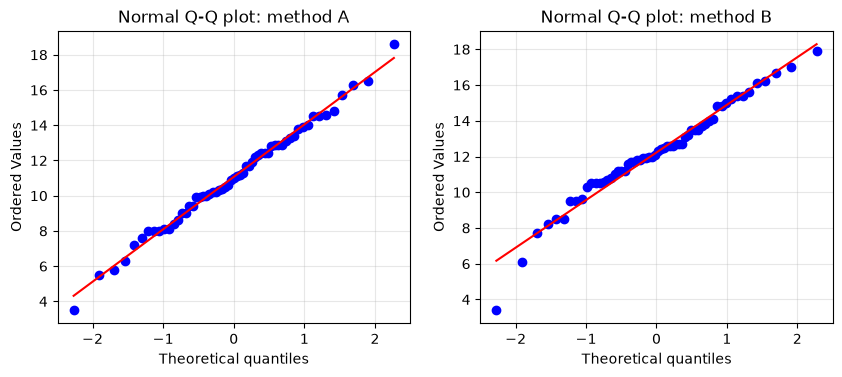

In [16]:
scores_ref = df.loc[df[GROUP_COL] == REFERENCE_GROUP, VALUE_COL].dropna()
scores_new = df.loc[df[GROUP_COL] == TREATED_GROUP, VALUE_COL].dropna()
samples = {f"{GROUP_COL} {REFERENCE_GROUP}": scores_ref, f"{GROUP_COL} {TREATED_GROUP}": scores_new}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for axis, (label, sample) in zip(axes, samples.items()):
    stats.probplot(sample, dist="norm", plot=axis)
    axis.set_title(f"Normal Q-Q plot: {label}")

for label, sample in samples.items():
    shapiro = stats.shapiro(sample)
    print(f"{label}: n = {len(sample)}, Shapiro-Wilk W = {shapiro.statistic:.3f}, p = {shapiro.pvalue:.3f}")

levene = stats.levene(scores_ref, scores_new)
print(f"Levene (equal variances?): statistic = {levene.statistic:.3f}, p = {levene.pvalue:.3f}")
plt.show()


**Reading the output.** If the Q-Q points hug the line and the Shapiro p-values are above $\alpha$, nothing contradicts normality. Levene's test compares the variances; whatever it says, Welch stays valid, which is why we chose it.

### Step 5: Computing the test by hand
The assignment asks you to **develop** the test, not just call a function. Welch's statistic and degrees of freedom are:

$$ t = \frac{\bar x_B - \bar x_A}{\sqrt{\dfrac{s_B^2}{n_B} + \dfrac{s_A^2}{n_A}}}, \qquad
\nu = \frac{\left(\dfrac{s_B^2}{n_B} + \dfrac{s_A^2}{n_A}\right)^2}{\dfrac{(s_B^2/n_B)^2}{n_B-1} + \dfrac{(s_A^2/n_A)^2}{n_A-1}} $$

where $\bar x$ is a sample mean, $s^2$ a sample variance and $n$ a sample size. The numerator is the observed difference; the denominator is its **standard error** (how much such a difference varies by chance alone). So $t$ = "difference measured in standard errors".

We then use the Student distribution with $\nu$ degrees of freedom:
- **p-value** (right-tailed) = probability, if H0 were true, of a $t$ at least this large: `stats.t.sf(t, ν)`;
- **critical value** = the $t$ that cuts off a right tail of area $\alpha$: `stats.t.ppf(1 - α, ν)`. The **rejection region** is $t > t_{crit}$.

In [17]:
def welch_statistics(sample_new, sample_ref):
    """/**
     * Welch t statistic, degrees of freedom and standard error of the difference,
     * computed from the formulas (no scipy test function involved).
     */"""
    variance_new = sample_new.var(ddof=1) / len(sample_new)
    variance_ref = sample_ref.var(ddof=1) / len(sample_ref)
    standard_error = np.sqrt(variance_new + variance_ref)
    t_value = (sample_new.mean() - sample_ref.mean()) / standard_error
    degrees = (variance_new + variance_ref) ** 2 / (
        variance_new ** 2 / (len(sample_new) - 1) + variance_ref ** 2 / (len(sample_ref) - 1)
    )
    return t_value, degrees, standard_error


t_value, degrees, standard_error = welch_statistics(scores_new, scores_ref)
difference = scores_new.mean() - scores_ref.mean()

p_one_sided = stats.t.sf(t_value, degrees)
p_two_sided = 2 * stats.t.sf(abs(t_value), degrees)
t_critical = stats.t.ppf(1 - ALPHA, degrees)

print(f"mean {TREATED_GROUP} - mean {REFERENCE_GROUP} = {difference:.3f} points")
print(f"standard error      = {standard_error:.3f}")
print(f"t statistic         = {t_value:.3f}   (degrees of freedom = {degrees:.1f})")
print(f"critical value      = {t_critical:.3f}   -> rejection region: t > {t_critical:.3f}")
print(f"p-value (one-sided) = {p_one_sided:.4f}")
print(f"p-value (two-sided) = {p_two_sided:.4f}   (twice the one-sided value)")


mean B - mean A = 1.159 points
standard error      = 0.511
t statistic         = 2.267   (degrees of freedom = 115.5)
critical value      = 1.658   -> rejection region: t > 1.658
p-value (one-sided) = 0.0126
p-value (two-sided) = 0.0253   (twice the one-sided value)


### Step 6: Checking against `scipy`
Never trust hand-written statistics blindly: compare them with the library. `ttest_ind(..., equal_var=False)` is Welch's test. The argument `alternative` sets the side: `"greater"` means H1: *mean of the first sample > mean of the second*, so **the order of the samples matters** (new first, reference second).

`np.isclose` returns `True` when two numbers agree up to rounding errors.

In [18]:
result = stats.ttest_ind(scores_new, scores_ref, equal_var=False, alternative="greater")

comparison = pd.DataFrame(
    {"by hand": [t_value, degrees, p_one_sided], "scipy": [result.statistic, result.df, result.pvalue]},
    index=["t statistic", "degrees of freedom", "p-value (one-sided)"],
)
comparison["agree"] = np.isclose(comparison["by hand"], comparison["scipy"])
comparison


,by hand,scipy,agree
t statistic,2.267,2.267,True
degrees of freedom,115.497,115.497,True
p-value (one-sided),0.013,0.013,True


### Step 7: Visualising the rejection region
The curve is the distribution of $t$ **if H0 were true**. The shaded area (area $\alpha$) is the rejection region. If our observed $t$ falls inside it, the data would be too surprising under H0.

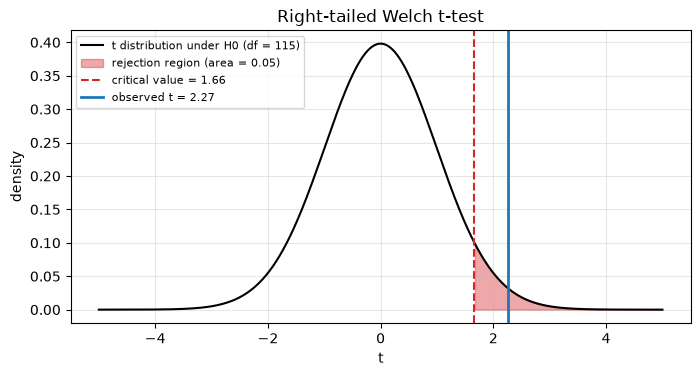

In [19]:
x_values = np.linspace(-5, max(5.0, t_value + 1), 500)
density = stats.t.pdf(x_values, degrees)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(x_values, density, color="black", label=f"t distribution under H0 (df = {degrees:.0f})")
ax.fill_between(x_values, density, where=x_values >= t_critical, alpha=0.4, color="tab:red",
                label=f"rejection region (area = {ALPHA})")
ax.axvline(t_critical, color="tab:red", linestyle="--", label=f"critical value = {t_critical:.2f}")
ax.axvline(t_value, color="tab:blue", linewidth=2, label=f"observed t = {t_value:.2f}")
ax.set(title="Right-tailed Welch t-test", xlabel="t", ylabel="density")
ax.legend(loc="upper left", fontsize=8)
plt.show()


### Step 8: Decision
Two equivalent rules; **they must always agree**:

- **p-value rule:** reject H0 if $p < \alpha$.
- **Rejection-region rule:** reject H0 if the observed $t$ lies in the region ($t > t_{crit}$).

> **What the p-value is *not*.** It is *not* the probability that H0 is true. It is the probability of data at least this extreme **assuming H0 is true**. And "fail to reject H0" does **not** prove H0: it only means the data did not provide enough evidence.

In [20]:
reject_by_p_value = p_one_sided < ALPHA
reject_by_region = t_value > t_critical
assert reject_by_p_value == reject_by_region, "the two decision rules must agree"

print(f"p-value rule : {p_one_sided:.4f} < {ALPHA} ? {reject_by_p_value}")
print(f"region rule  : {t_value:.3f} > {t_critical:.3f} ? {reject_by_region}")
print("Decision     :", "reject H0" if reject_by_p_value else "fail to reject H0")


p-value rule : 0.0126 < 0.05 ? True
region rule  : 2.267 > 1.658 ? True
Decision     : reject H0


### Step 9: Beyond the p-value: confidence interval and effect size
A p-value says *whether* an effect is detectable, not *how big* it is. With a very large sample, a tiny and useless difference can be "significant". So always add:

- a **95 % confidence interval** for the difference (two-sided): $(\bar x_B - \bar x_A) \pm t_{1-\alpha/2,\,\nu}\times SE$;
- an **effect size**. **Cohen's d** expresses the difference in pooled standard deviations: $d = \dfrac{\bar x_B - \bar x_A}{s_p}$. Rough conventions: 0.2 small, 0.5 medium, 0.8 large (they are conventions, not laws; judge it in your context).

In [21]:
def cohens_d(sample_new, sample_ref):
    """/** Cohen's d with the pooled standard deviation. */"""
    n_new, n_ref = len(sample_new), len(sample_ref)
    pooled_variance = ((n_new - 1) * sample_new.var(ddof=1) + (n_ref - 1) * sample_ref.var(ddof=1)) / (n_new + n_ref - 2)
    return (sample_new.mean() - sample_ref.mean()) / np.sqrt(pooled_variance)


margin = stats.t.ppf(1 - ALPHA / 2, degrees) * standard_error
ci_low, ci_high = difference - margin, difference + margin
effect_size = cohens_d(scores_new, scores_ref)

"""/** Cross-check the interval with scipy (available on the two-sided result). */"""
scipy_ci = stats.ttest_ind(scores_new, scores_ref, equal_var=False).confidence_interval(1 - ALPHA)
print(f"{1 - ALPHA:.0%} CI of the difference (by hand): [{ci_low:.3f}, {ci_high:.3f}]")
print(f"{1 - ALPHA:.0%} CI of the difference (scipy)  : [{scipy_ci.low:.3f}, {scipy_ci.high:.3f}]")
print(f"Cohen's d = {effect_size:.2f}")


95% CI of the difference (by hand): [0.146, 2.172]
95% CI of the difference (scipy)  : [0.146, 2.172]
Cohen's d = 0.42


### Step 10: Global conclusion and governance choice
The assignment asks for a conclusion **and** a *governance choice* ("what do we do about it?"). A good conclusion has four parts: **statistical decision → size of the effect → limits → decision for the organisation.** The next cell assembles the factual part from the computed values, so it always matches the numbers.

In [22]:
verdict = "reject H0" if reject_by_p_value else "fail to reject H0"
print(f"""At alpha = {ALPHA}, we {verdict} (one-sided Welch t-test: t = {t_value:.2f}, df = {degrees:.1f}, p = {p_one_sided:.4f}).
Mean score: {scores_new.mean():.2f} with method {TREATED_GROUP} (n = {len(scores_new)}) versus {scores_ref.mean():.2f} with method {REFERENCE_GROUP} (n = {len(scores_ref)}).
Difference = {difference:+.2f} points, {1 - ALPHA:.0%} CI [{ci_low:.2f}, {ci_high:.2f}], Cohen's d = {effect_size:.2f}.""")


At alpha = 0.05, we reject H0 (one-sided Welch t-test: t = 2.27, df = 115.5, p = 0.0126).
Mean score: 12.23 with method B (n = 60) versus 11.07 with method A (n = 59).
Difference = +1.16 points, 95% CI [0.15, 2.17], Cohen's d = 0.42.


**(Simulation only) Checking against the truth.** Because we generated the data, we know the real advantage of method B. With real data this is impossible, which is exactly why we need statistics. The cell below is skipped automatically when `TRUE_EFFECT_B` does not exist (your own dataset).

In [23]:
if "TRUE_EFFECT_B" in globals():
    inside = ci_low <= TRUE_EFFECT_B <= ci_high
    print(f"Built-in effect = {TRUE_EFFECT_B:+.1f} points | {1 - ALPHA:.0%} CI = [{ci_low:.2f}, {ci_high:.2f}] | CI contains the truth: {inside}")
    print(f"Estimated difference = {difference:+.2f} (estimation error = {difference - TRUE_EFFECT_B:+.2f}, standard error = {standard_error:.2f})")
else:
    print("No built-in effect defined: real data, nothing to compare with.")


Built-in effect = +2.0 points | 95% CI = [0.15, 2.17] | CI contains the truth: True
Estimated difference = +1.16 (estimation error = -0.84, standard error = 0.51)


**From result to decision.** Turn the numbers into a choice, and justify it with the *cost of being wrong*:

| Situation | Possible governance choice |
|---|---|
| H0 rejected **and** effect large enough to matter in practice | Adopt the new method (ideally start with a controlled roll-out and monitor) |
| H0 rejected **but** effect tiny, or its CI includes only trivial values | Statistically real but practically minor: weigh it against the cost of switching |
| H0 **not** rejected, wide CI | Inconclusive, not "no effect": collect more data before deciding |
| H0 **not** rejected, narrow CI around 0 | Reasonable evidence of no meaningful effect: keep the cheaper option |

**Always state the limits:** sample size, how groups were formed (random assignment supports causal claims, observation does not), data-quality issues, and that one test never proves anything for ever.

## 7. A second test: chi-square of independence (Q2)

**Question:** is *passing* linked to the *method*? Both variables are qualitative → **chi-square test of independence**.

- **H0:** the two variables are independent (the pass rate is the same for both methods).
- **H1:** they are associated (the pass rate depends on the method). Chi-square is naturally **two-sided**.

**Principle:** compare the observed counts with the counts *expected* if H0 were true (row total × column total / grand total). The statistic $\chi^2 = \sum \frac{(O - E)^2}{E}$ grows when observed and expected counts differ.

**Condition (rule of thumb):** every *expected* count should be at least 5; otherwise the test is unreliable. For a 2×2 table scipy applies a continuity correction (Yates) by default.

In [24]:
contingency = pd.crosstab(df[GROUP_COL], df[CATEGORY_COL])
chi2_result = stats.chi2_contingency(contingency)

expected = pd.DataFrame(chi2_result.expected_freq, index=contingency.index, columns=contingency.columns)
print("Observed counts:\n", contingency, "\n")
print("Expected counts under H0:\n", expected.round(1), "\n")
print("smallest expected count:", round(expected.to_numpy().min(), 1), "(>= 5 required)")
print(f"chi2 = {chi2_result.statistic:.3f}, dof = {chi2_result.dof}, p-value = {chi2_result.pvalue:.4f}")
print("Decision:", "reject H0 (association)" if chi2_result.pvalue < ALPHA else "fail to reject H0 (no evidence of association)")


Observed counts:
 passed  no  yes
method         
A       19   40
B        9   51 

Expected counts under H0:
 passed    no   yes
method            
A       13.9  45.1
B       14.1  45.9 

smallest expected count: 13.9 (>= 5 required)
chi2 = 3.984, dof = 1, p-value = 0.0459
Decision: reject H0 (association)


**Reading it.**
- If $p \ge \alpha$ we do **not** conclude "the methods have the same pass rate": we only say the data do not show a detectable link.
- If $p$ is **close to** $\alpha$ (as in the default example, where it is just below 0.05), call the result *borderline* and say so. A tiny change in the data could flip it, so 0.049 and 0.051 are not "night and day".
- Compare with Q1: turning a score into yes/no throws information away, which lowers the **power** of the test. In the default example the chi-square p-value is much larger than the t-test's, although both point the same way.

## 8. Simple linear regression (Q3)

**Model:** $y = a + b\,x + \varepsilon$, with $y$ = exam score, $x$ = weekly study hours. The slope $b$ is *the average change in score for one more hour*. `stats.linregress` returns the slope, intercept, correlation $r$ (so $R^2 = r^2$ is the share of variance explained), the **p-value of the slope** (test of H0: $b = 0$, two-sided) and the slope's standard error.

**Missing values:** regression needs both variables, so we drop incomplete rows **for this analysis only** (the t-test already used them).

**Assumptions to inspect:** linear relationship; residuals with roughly constant spread (homoscedasticity) and no pattern; roughly normal residuals; independent observations.

In [25]:
pairs = df[[X_COL, VALUE_COL]].dropna()
print(f"rows used: {len(pairs)} (dropped {len(df) - len(pairs)} with a missing value)")

fit = stats.linregress(pairs[X_COL], pairs[VALUE_COL])
slope_margin = stats.t.ppf(1 - ALPHA / 2, len(pairs) - 2) * fit.stderr

print(f"slope     = {fit.slope:.3f} points per extra hour  ({1 - ALPHA:.0%} CI "
      f"[{fit.slope - slope_margin:.3f}, {fit.slope + slope_margin:.3f}])")
print(f"intercept = {fit.intercept:.3f}")
print(f"r = {fit.rvalue:.3f}, R2 = {fit.rvalue ** 2:.3f}")
print(f"p-value of the slope = {fit.pvalue:.2e}")


rows used: 113 (dropped 6 with a missing value)
slope     = 0.317 points per extra hour  (95% CI [0.223, 0.410])
intercept = 7.667
r = 0.537, R2 = 0.289
p-value of the slope = 8.56e-10


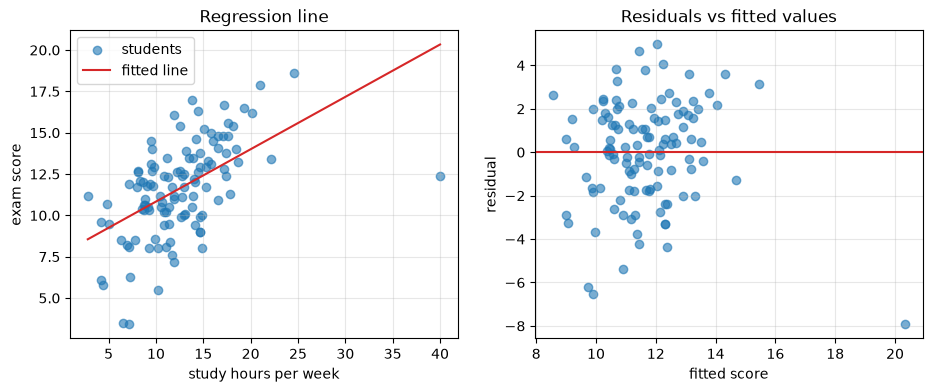

In [26]:
fitted = fit.intercept + fit.slope * pairs[X_COL]
residuals = pairs[VALUE_COL] - fitted

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(pairs[X_COL], pairs[VALUE_COL], alpha=0.6, label="students")
line_x = np.array([pairs[X_COL].min(), pairs[X_COL].max()])
axes[0].plot(line_x, fit.intercept + fit.slope * line_x, color="tab:red", label="fitted line")
axes[0].set(title="Regression line", xlabel="study hours per week", ylabel="exam score")
axes[0].legend()

axes[1].scatter(fitted, residuals, alpha=0.6)
axes[1].axhline(0, color="tab:red")
axes[1].set(title="Residuals vs fitted values", xlabel="fitted score", ylabel="residual")

plt.show()


**Reading the plots.** Left: does the line follow the cloud? Right: residuals should look like a *formless band around 0*. A curve means the relationship is not linear; a funnel means the spread changes (heteroscedasticity).

**Does the extreme value matter?** Never remove an outlier just because it is inconvenient. Instead, run the analysis **with and without** it and compare three things: does the *sign* change? does the *significance* change? does the *size* of the slope change a lot? If the answers are no, no and no, the result is robust. If only the size moves, report both versions.

In [27]:
without_outliers = pairs[~iqr_outlier_mask(pairs[X_COL])]
fit_without = stats.linregress(without_outliers[X_COL], without_outliers[VALUE_COL])

sensitivity = pd.DataFrame(
    {"rows": [len(pairs), len(without_outliers)],
     "slope": [fit.slope, fit_without.slope],
     "R2": [fit.rvalue ** 2, fit_without.rvalue ** 2],
     "p-value": [fit.pvalue, fit_without.pvalue]},
    index=["all rows", f"without {X_COL} outliers"],
)
print(sensitivity)
change = (fit_without.slope - fit.slope) / fit.slope * 100
removed = len(pairs) - len(without_outliers)
print(f"\nThe slope changes by {change:+.0f}% when the {removed} flagged value(s) of {X_COL} are removed.")


                              rows  slope     R2    p-value
all rows                       113  0.317  0.289  8.564e-10
without study_hours outliers   111  0.423  0.355  5.376e-12



The slope changes by +34% when the 2 flagged value(s) of study_hours are removed.


**Careful with interpretation.** A significant slope shows an **association**, not necessarily a **cause** (a hidden variable could drive both). Do not extrapolate far outside the observed range of $x$. If you need several explanatory variables at once (multiple regression), that is where a library such as `statsmodels` (Level 5) becomes useful.

## 9. Conclusion template, checklist and cheat sheet

### 9.1 Conclusion template (write it in your own words, in French)
1. **Main findings:** one sentence per question (Q1, Q2, Q3) with the key number (difference, p-value, effect size).
2. **What it means** for your initial context.
3. **Limits of the data:** sample size, collection method, missing/erroneous values, representativeness.
4. **Limits of the methods:** assumptions that are only roughly satisfied, tests chosen, multiple testing.
5. **Possible next steps.**

### 9.2 Checklist against the assignment
| Requirement (from the instructions) | Where here |
|---|---|
| Granularity of the dataset | Part 2 |
| Variables, types and meaning | Part 2 (data dictionary) |
| Critique of data quality | Part 4 |
| Descriptive methods, graphical and numerical | Part 5 |
| Appropriate significance level | Part 6, step 3 |
| H0 / H1, one- or two-sided, and why | Part 6, step 2 |
| Test developed and justified | Part 6, steps 4 to 6 |
| Conclusion from the p-value **and** the rejection region | Part 6, steps 7 and 8 |
| Global conclusion with a governance choice | Part 6, step 10 |
| Principal findings and limits | Part 9.1 |
| Sources cited, raw (and cleaned) data delivered | Part 2 / `CSV_RAW`, `CSV_CLEAN` |

### 9.3 Which test when? (cheat sheet)
| Situation | Test | `scipy.stats` function |
|---|---|---|
| Compare one mean with a known value | One-sample t-test | `ttest_1samp` |
| Compare 2 independent means | Welch t-test | `ttest_ind(equal_var=False)` |
| Compare 2 measurements on the same subjects | Paired t-test | `ttest_rel` |
| Compare 3 or more means | One-way ANOVA | `f_oneway` |
| 2 groups, clearly non-normal / small samples | Mann-Whitney U | `mannwhitneyu` |
| 3 or more groups, non-normal | Kruskal-Wallis | `kruskal` |
| Paired data, non-normal | Wilcoxon signed-rank | `wilcoxon` |
| Two qualitative variables | Chi-square of independence | `chi2_contingency` |
| Linear relation between 2 quantitative variables | Pearson correlation / simple regression | `pearsonr`, `linregress` |
| Monotonic relation, ordinal data or outliers | Spearman correlation | `spearmanr` |
| Is a sample normal? | Shapiro-Wilk | `shapiro` |
| Equal variances? | Levene | `levene` |

The next cell checks that every function named in the table exists in **your** installed version of scipy.

In [28]:
cheat_sheet_functions = ["ttest_1samp", "ttest_ind", "ttest_rel", "f_oneway", "mannwhitneyu", "kruskal",
                         "wilcoxon", "chi2_contingency", "pearsonr", "linregress", "spearmanr", "shapiro", "levene"]
missing_functions = [name for name in cheat_sheet_functions if not hasattr(stats, name)]
print("functions checked:", len(cheat_sheet_functions), "| missing in this scipy version:", missing_functions or "none")


functions checked: 13 | missing in this scipy version: none


### 9.4 Common mistakes to avoid
- Choosing **one-sided** after seeing which direction the data go.
- Reading "p > 0.05" as "no effect" (it means *not enough evidence*).
- Reporting only a p-value: add the **effect size** and a **confidence interval**.
- Running many tests and reporting only the significant ones (**multiple testing** inflates false alarms).
- Dropping outliers or missing data silently: always document and justify.
- Forgetting the **random seed** and library versions: results must be reproducible.
- Confusing **association** with **causation**.

### 9.5 Adapting this notebook to your own dataset
1. Put your raw CSV next to the notebook and **never edit it**.
2. Skip the synthetic generator cell and edit the **configuration cell** (column names, groups, valid range, $\alpha$).
3. Re-run Parts 3 to 5 and **read the outputs critically**: your data will have its own flaws.
4. Choose your tests from the cheat sheet; write hypotheses and justifications **in your own words**.
5. Cite every data source and every external resource you used.